# Trip-Mix HMM: Discovering Citi Bike Usage Modes

Design write-up: [`TRIP_MIX_HMM.md`](TRIP_MIX_HMM.md).

**Idea.** Label every Citi Bike trip with a *trip type* (member/casual, short/long, direction relative to the
Manhattan core, round trip). Observe each hour of the day as the **mix of trip types** across the city, and
fit an HMM whose hidden states are *usage modes*. Each state is a distribution over trip types, so states
can't differ in volume (busy vs. quiet) and have to differ in *how* the city is riding.

**Notebook outline**
1. Data: download, classify trips, build an hourly (day × hour × trip type) table; calendar + weather
2. Model: a multinomial-emission HMM (hmmlearn subclass) with tempered counts
3. Choosing the number of states K
4. Interpreting the final model: emissions, transitions, Viterbi calendar
5. Are the states meaningful? Mutual information, holidays, weather
6. Prediction vs. baselines
7. Ablations: N_eff, trip-type alphabet, volume- vs. mix-based observations
8. Stretch: a day-level HMM on top of the hourly states

In [1]:
import logging
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.patches import Patch
from matplotlib.path import Path as MplPath
from pandas.tseries.holiday import USFederalHolidayCalendar
from sklearn.metrics import mutual_info_score
from hmmlearn import hmm
from hmmlearn.base import BaseHMM

logging.getLogger("hmmlearn").setLevel(logging.ERROR)  # silences MultinomialHMM's API-change notice

MONTHS = pd.period_range("2025-10", "2026-09", freq="M").strftime("%Y%m").tolist()
RAW_DIR = Path("citibike-tripdata") # monthly zips (downloaded automatically if missing)
CACHE_DIR = Path("data")
S3_URL = "https://s3.amazonaws.com/tripdata/{month}-citibike-tripdata.zip"

N_EFF = 50          # tempering: each hour counts as N_EFF effective trips (see section 2)
N_RESTARTS = 10     # EM restarts per fit
EM_TOL = 0.1        # stop EM when log-likelihood improves by less than this (LL is ~1e5, so ~1e-6 relative)
K_RANGE = range(2, 10)
SEED = 0

# Plot styling: fixed categorical order for hidden states, recessive chrome.
STATE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#184f95", "#86b6ef", "#f0efec", "#ec835a", "#b8302f"])
SEQUENTIAL = LinearSegmentedColormap.from_list("blues", ["#f0efec", "#9ec5f4", "#3987e5", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.grid": False, "grid.color": "#e1e0d9", "font.size": 9, "axes.titlesize": 10,
    "axes.titleweight": "bold", "legend.frameon": False,
})

## 1. Data

### 1.1 Trip types

Every trip gets a **fine-grained key** (17 values: rider type × short/long × direction, plus round trip). The
per-month cache stores counts of these keys so the ablations in section 7 can merge them into coarser
alphabets without re-reading the raw data. The main model uses the 8-type alphabet below.

| # | Type | Rule |
|---|---|---|
| 0 | `member_into_core` | member, < 20 min, starts outside core, ends inside |
| 1 | `member_out_of_core` | member, < 20 min, starts inside core, ends outside |
| 2 | `member_within_core` | member, < 20 min, both ends in core |
| 3 | `member_outer` | member, < 20 min, both ends outside core |
| 4 | `member_long` | member, ≥ 20 min |
| 5 | `casual_short` | casual, < 20 min |
| 6 | `casual_long` | casual, ≥ 20 min |
| 7 | `round_trip` | start station = end station (takes priority) |

**Core** = Manhattan south of ~59th St, approximated by the polygon below. **Cleaning:** drop trips under 1 min
or over 3 h, and trips with no end location. **Service day** = 4 AM → 4 AM, so late-night rides belong to the
evening before.

In [2]:
CORE_POLYGON = MplPath(np.array([   # (lng, lat), Manhattan below ~59th St, clockwise from the Battery
    (-74.0190, 40.7005), (-74.0080, 40.7040), (-73.9990, 40.7075), (-73.9760, 40.7100),
    (-73.9710, 40.7280), (-73.9715, 40.7440), (-73.9580, 40.7580), (-73.9940, 40.7720),
    (-74.0060, 40.7590), (-74.0120, 40.7400), (-74.0150, 40.7200), (-74.0200, 40.7050),
]))
DIRECTIONS = ["into_core", "out_of_core", "within_core", "outer"]
SHORT_MINUTES = 20
ROUND_TRIP_KEY = 16   # fine key = 8*member + 4*long + direction, or 16 for a round trip
TRIP_COLUMNS = ["started_at", "ended_at", "start_station_name", "end_station_name",
                "start_lat", "start_lng", "end_lat", "end_lng", "member_casual"]


def classify_trips(trips):
    """Return (service_date, hour, fine_key) for every valid trip."""
    started = pd.to_datetime(trips.started_at, format="ISO8601")
    minutes = (pd.to_datetime(trips.ended_at, format="ISO8601") - started).dt.total_seconds() / 60
    keep = (minutes >= 1) & (minutes <= 180) & trips.end_lat.notna() & trips.start_lat.notna()
    trips, started, minutes = trips[keep], started[keep], minutes[keep]

    start_core = CORE_POLYGON.contains_points(trips[["start_lng", "start_lat"]].to_numpy())
    end_core = CORE_POLYGON.contains_points(trips[["end_lng", "end_lat"]].to_numpy())
    direction = np.select([~start_core & end_core, start_core & ~end_core, start_core & end_core], [0, 1, 2], default=3)
    member = (trips.member_casual == "member").to_numpy()
    long = (minutes >= SHORT_MINUTES).to_numpy()
    round_trip = (trips.start_station_name == trips.end_station_name).to_numpy()
    fine_key = np.where(round_trip, ROUND_TRIP_KEY, 8 * member + 4 * long + direction)

    return pd.DataFrame({
        "service_date": (started - pd.Timedelta(hours=4)).dt.normalize().to_numpy(),
        "hour": started.dt.hour.to_numpy(),
        "fine_key": fine_key,
    })


def load_month_counts(month):
    """Hourly fine-key counts for one month, cached to data/counts/<month>.csv."""
    cache = CACHE_DIR / "counts" / f"{month}.csv"
    if cache.exists():
        return pd.read_csv(cache, parse_dates=["service_date"])
    zip_path = RAW_DIR / f"{month}-citibike-tripdata.zip"
    if not zip_path.exists():
        RAW_DIR.mkdir(exist_ok=True)
        print(f"downloading {zip_path.name} ...")
        urllib.request.urlretrieve(S3_URL.format(month=month), zip_path)
    parts = []
    with zipfile.ZipFile(zip_path) as z:
        for name in sorted(n for n in z.namelist() if n.endswith(".csv") and "__MACOSX" not in n):
            with z.open(name) as f:
                trips = pd.read_csv(f, usecols=TRIP_COLUMNS, engine="pyarrow")
            parts.append(classify_trips(trips).value_counts().rename("n").reset_index())
    counts = pd.concat(parts).groupby(["service_date", "hour", "fine_key"], as_index=False).n.sum()
    cache.parent.mkdir(parents=True, exist_ok=True)
    counts.to_csv(cache, index=False)
    return counts


counts = (pd.concat([load_month_counts(m) for m in MONTHS])
          .groupby(["service_date", "hour", "fine_key"]).n.sum())
print(f"{counts.sum():,} trips")

45,197,443 trips


### 1.2 Hourly table and data-quality check

Reshape to one row per (service day, hour) with 17 fine-key columns. Hours run 4 AM → 3 AM. The first and
last service days are partial (they straddle the data window), so they're dropped. We also flag days with
**zero-trip hours between 7 AM and 10 PM**. NYC always has some riders in those hours, so system-wide zeros
mean the service was off or the published files have a gap.

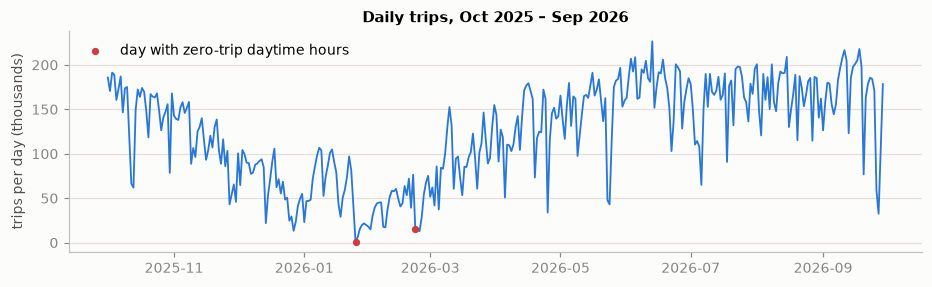

days with zero-trip daytime hours: 2
service_date
2026-01-25    9
2026-02-22    1


In [3]:
SERVICE_HOURS = [*range(4, 24), *range(4)]
all_dates = counts.index.get_level_values("service_date").unique().sort_values()
dates = all_dates[1:-1]
hourly_fine = (counts.unstack("fine_key", fill_value=0)
               .reindex(columns=range(17), fill_value=0)
               .reindex(pd.MultiIndex.from_product([dates, SERVICE_HOURS], names=["service_date", "hour"]), fill_value=0))

daily_total = hourly_fine.sum(axis=1).groupby(level="service_date").sum()
daytime = hourly_fine.sum(axis=1).unstack("hour")[list(range(7, 22))]
gap_hours = (daytime == 0).sum(axis=1)

fig, ax = plt.subplots(figsize=(10, 2.6))
ax.plot(daily_total.index, daily_total / 1e3, color="#2a78d6", lw=1.2)
bad = gap_hours[gap_hours > 0].index
ax.scatter(bad, daily_total[bad] / 1e3, color="#d03b3b", s=14, zorder=3, label="day with zero-trip daytime hours")
ax.set_ylabel("trips per day (thousands)")
ax.set_title("Daily trips, Oct 2025 – Sep 2026")
ax.legend(loc="upper left")
ax.grid(axis="y")
plt.show()

print("days with zero-trip daytime hours:", len(bad))
print(gap_hours[gap_hours > 0].to_string())

The two flagged days are **Jan 25, 2026 (~20 cm of snow)** and **Feb 22, 2026 (~9 cm)**, both major snowstorms
(see the weather data in 1.4). The zero-trip hours are consistent with Citi Bike suspending service. Days with
more than `MAX_GAP_HOURS` zero-trip daytime hours are excluded: an hour with no trips has no mix to observe, so
the model would only be guessing through it. The Feb 22 storm (1 zero hour) and every other quiet day (rain,
lighter snow, holidays) are kept, since those are exactly the days we want the model to handle.

**Feb 23, 2026** (the second day of the same storm, ~13 cm of snow) has **no trips at all**, so it never appears
in the data. Hourly sequences are per day, so this doesn't affect them. The day-level HMM in section 8 splits
its sequence at missing dates.

In [4]:
MAX_GAP_HOURS = 2
dates = dates[gap_hours.reindex(dates).to_numpy() <= MAX_GAP_HOURS]
hourly_fine = hourly_fine.loc[dates]
n_days = len(dates)
print(f"{n_days} usable service days, {dates[0].date()} → {dates[-1].date()}")

362 usable service days, 2025-10-01 → 2026-09-29


### 1.3 Trip-type alphabets

An *alphabet* maps the 17 fine keys onto the observation symbols. `full` is the main 8-type alphabet. The
other two are used in the ablations (section 7).

In [5]:
def fine_label(key):
    if key == ROUND_TRIP_KEY:
        return "round_trip"
    rider = "member" if key >= 8 else "casual"
    length = "long" if key % 8 >= 4 else "short"
    return f"{rider}_{length}_{DIRECTIONS[key % 4]}"


def full_type(label):
    if label == "round_trip":
        return "round_trip"
    rider, length, direction = label.split("_", 2)
    if rider == "casual":
        return f"casual_{length}"
    return "member_long" if length == "long" else f"member_{direction}"


TRIP_TYPES = ["member_into_core", "member_out_of_core", "member_within_core", "member_outer",
              "member_long", "casual_short", "casual_long", "round_trip"]


def no_direction_type(label):
    t = full_type(label)
    return "member_short" if t in TRIP_TYPES[:4] else t


def no_rider_type(label):
    if label == "round_trip":
        return "round_trip"
    _, length, direction = label.split("_", 2)
    return "long" if length == "long" else f"short_{direction}"


ALPHABETS = {"full": full_type, "no_direction": no_direction_type, "no_rider_type": no_rider_type}


def alphabet_counts(name):
    """(n_days*24, n_symbols) count matrix and symbol names for an alphabet."""
    labels = pd.Series({k: ALPHABETS[name](fine_label(k)) for k in range(17)})
    symbols = TRIP_TYPES if name == "full" else list(dict.fromkeys(labels))
    grouped = hourly_fine.T.groupby(labels.reindex(hourly_fine.columns).to_numpy()).sum().T
    return grouped[symbols].to_numpy(float), symbols


X_counts, _ = alphabet_counts("full")
overall_mix = X_counts.sum(0) / X_counts.sum()
pd.Series(overall_mix, index=TRIP_TYPES).map("{:.1%}".format).to_frame("share of all trips")

,share of all trips
member_into_core,3.5%
member_out_of_core,3.3%
member_within_core,30.6%
member_outer,33.6%
member_long,10.5%
casual_short,12.0%
casual_long,4.5%
round_trip,2.0%


The mix changes over the day. Here's the average share of each trip type by hour, weekdays vs. weekends.
This is the raw signal the HMM has to explain.

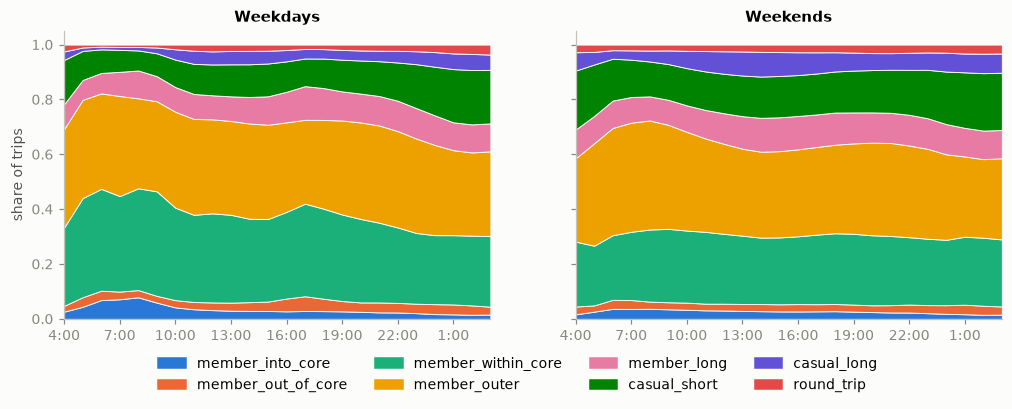

In [6]:
mix_by_hour = pd.DataFrame(X_counts, columns=TRIP_TYPES,
                           index=hourly_fine.index).groupby(
    [hourly_fine.index.get_level_values("service_date").dayofweek >= 5,
     hourly_fine.index.get_level_values("hour")]).sum()
mix_by_hour = mix_by_hour.div(mix_by_hour.sum(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, weekend in zip(axes, [False, True]):
    shares = mix_by_hour.loc[weekend].reindex(SERVICE_HOURS)
    ax.stackplot(range(24), shares.T.to_numpy(), colors=STATE_COLORS, edgecolor="#fcfcfb", linewidth=0.6)
    ax.set_xticks(range(0, 24, 3), [f"{h}:00" for h in SERVICE_HOURS[::3]])
    ax.set_title("Weekends" if weekend else "Weekdays")
    ax.set_xlim(0, 23)
axes[0].set_ylabel("share of trips")
fig.legend([Patch(color=c) for c in STATE_COLORS], TRIP_TYPES, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.12))
plt.show()

### 1.4 Calendar and weather

- **Holidays:** the pandas US federal calendar. Six "major" holidays (most offices closed) define
  `workday = Mon–Fri and not a major holiday`. The *minor* federal holidays (Columbus, Veterans, MLK,
  Presidents, Juneteenth) are kept as workdays. Whether the model treats them like workdays is one of the
  checks in section 5.
- **Weather:** hourly precipitation, snowfall and temperature at Central Park from the Open-Meteo historical
  archive (no API key needed). A **wet hour** has ≥ 0.5 mm of precipitation. A **rainy day** has ≥ 5 mm
  between 7 AM and 9 PM.

The model never sees any of these. They're only used to interpret it afterwards.

In [7]:
MAJOR_HOLIDAYS = {"New Year's Day", "Memorial Day", "Independence Day", "Labor Day", "Thanksgiving Day", "Christmas Day"}

days = pd.DataFrame(index=dates)
days["weekday"] = dates.day_name()
days["holiday"] = USFederalHolidayCalendar().holidays(dates[0], dates[-1], return_name=True).reindex(dates)
days["workday"] = (dates.dayofweek < 5) & ~days.holiday.isin(MAJOR_HOLIDAYS)


def load_weather():
    cache = CACHE_DIR / "weather_hourly.csv"
    if not cache.exists():
        url = ("https://archive-api.open-meteo.com/v1/archive?latitude=40.7829&longitude=-73.9654"
               f"&start_date={dates[0].date()}&end_date={(dates[-1] + pd.Timedelta(days=1)).date()}"
               "&hourly=temperature_2m,precipitation,snowfall&timezone=America%2FNew_York&format=csv")
        cache.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(url, cache)
    weather = pd.read_csv(cache, skiprows=3)   # Open-Meteo CSV has a 3-line location header
    weather.columns = ["time", "temp_c", "precip_mm", "snow_cm"]
    t = pd.to_datetime(weather.time)
    weather["service_date"] = (t - pd.Timedelta(hours=4)).dt.normalize()
    weather["hour"] = t.dt.hour
    return weather.groupby(["service_date", "hour"])[["temp_c", "precip_mm", "snow_cm"]].mean()


weather = load_weather().reindex(hourly_fine.index)
riding_hours = weather.index.get_level_values("hour").isin(range(7, 22))
days["rain_mm"] = weather.precip_mm[riding_hours].groupby(level="service_date").sum()
days["snow_cm"] = weather.snow_cm.groupby(level="service_date").sum()
days["max_temp_c"] = weather.temp_c.groupby(level="service_date").max()
days["rainy"] = days.rain_mm >= 5

print(days.holiday.dropna().to_string())
print(f"\nworkdays: {days.workday.sum()}, non-workdays: {(~days.workday).sum()}, rainy days: {days.rainy.sum()}")

service_date
2025-10-13                            Columbus Day
2025-11-11                            Veterans Day
2025-11-27                        Thanksgiving Day
2025-12-25                           Christmas Day
2026-01-01                          New Year's Day
2026-01-19     Birthday of Martin Luther King, Jr.
2026-02-16                   Washington's Birthday
2026-05-25                            Memorial Day
2026-06-19    Juneteenth National Independence Day
2026-07-03                        Independence Day
2026-09-07                               Labor Day

workdays: 253, non-workdays: 109, rainy days: 50


## 2. Model

### 2.1 Multinomial-emission HMM

Each hidden state `i` has a distribution `B[i,:]` over trip types. An hour's observation is the vector of
trip-type counts, and each trip is a draw from the current state's distribution:

$$\log P(x_t \mid z_t = i) = \sum_k n_{t,k}\,\log B_{i,k} \;+\; \text{const}$$

This is the discrete HMM from class, except each hour emits a *bag* of symbols. hmmlearn's `MultinomialHMM`
already implements Baum–Welch for this model. Its emission M-step is
$B_{i,k} \propto \sum_t \gamma_t(i)\, n_{t,k}$, the expected trip-type counts while in state $i$. The subclass
below changes only two things:
- it accepts **non-integer counts** (needed for tempering), and
- it drops the multinomial coefficient, which is the same for every state, so it doesn't affect posteriors,
  Viterbi or EM.

### 2.2 Tempering

Busy hours have ~15,000 trips. Read literally as independent draws, the log-likelihood is so large that every
posterior is 0/1 and more states always "win". Trips in the same hour aren't really independent (weather,
events and groups move riders together), so each hour is rescaled to **`N_EFF` effective trips**:
$x_t \leftarrow N_{\text{eff}} \cdot x_t / \sum_k x_{t,k}$. Section 7.1 varies `N_EFF`.

In [8]:
class TripMixHMM(hmm.MultinomialHMM):
    """MultinomialHMM that accepts fractional (tempered) counts."""

    def _check_and_set_n_features(self, X):
        BaseHMM._check_and_set_n_features(self, X)
        if X.min() < 0:
            raise ValueError("counts must be non-negative")
        self.n_trials = X.sum(axis=1)

    def _compute_log_likelihood(self, X):
        return X @ np.log(np.clip(self.emissionprob_, 1e-300, None)).T

    def _compute_likelihood(self, X):
        return np.exp(self._compute_log_likelihood(X))


def temper(X, n_eff=N_EFF):
    """Rescale each hour to n_eff effective trips (n_eff=None keeps raw counts)."""
    if n_eff is None:
        return X
    totals = X.sum(axis=1, keepdims=True)
    return np.divide(n_eff * X, totals, out=np.zeros_like(X), where=totals > 0)


def make_trip_mix_hmm(K, seed, X):
    """Emissions start at the (smoothed) mixes of K random hours; start/transition probs are random."""
    rng = np.random.default_rng(seed)
    model = TripMixHMM(n_components=K, n_iter=500, tol=EM_TOL, random_state=seed, init_params="st")
    seeds = X[rng.choice(len(X), K, replace=False)] + 0.5
    model.emissionprob_ = seeds / seeds.sum(axis=1, keepdims=True)
    return model


def fit_best(make_model, X, lengths, n_restarts=N_RESTARTS):
    """Fit n_restarts EM runs and keep the one with the highest training log-likelihood.
    A restart where a state loses all probability mass (NaN parameters) is skipped."""
    fits, scores = [], []
    for r in range(n_restarts):
        try:
            model = make_model(SEED + r).fit(X, lengths)
            fits.append(model)
            scores.append(model.score(X, lengths))
        except ValueError:
            continue
    scores = np.array(scores)
    return fits[int(scores.argmax())], scores

### 2.3 Train / test split

Whole service days are held out (never part of a day), 20% at random. Each day is one sequence of 24 hourly
observations.

In [9]:
rng = np.random.default_rng(SEED)
test_mask = np.zeros(n_days, bool)
test_mask[rng.choice(n_days, n_days // 5, replace=False)] = True
train_days, test_days = np.flatnonzero(~test_mask), np.flatnonzero(test_mask)


def day_rows(X, day_idx):
    """Rows of an hourly (n_days*24, ·) matrix belonging to the given days, plus hmmlearn lengths."""
    return X[(day_idx[:, None] * 24 + np.arange(24)).ravel()], [24] * len(day_idx)


X = temper(X_counts)
X_train, len_train = day_rows(X, train_days)
X_test, len_test = day_rows(X, test_days)
print(f"train: {len(train_days)} days, test: {len(test_days)} days")

train: 290 days, test: 72 days


## 3. Choosing the number of states K

For K = 2…9: fit on the training days (10 restarts each), then record:
- **held-out log-likelihood per hour** (higher is better),
- **BIC** on training data (lower is better),
- the spread of final log-likelihoods across restarts (a stability check: EM finds local optima).

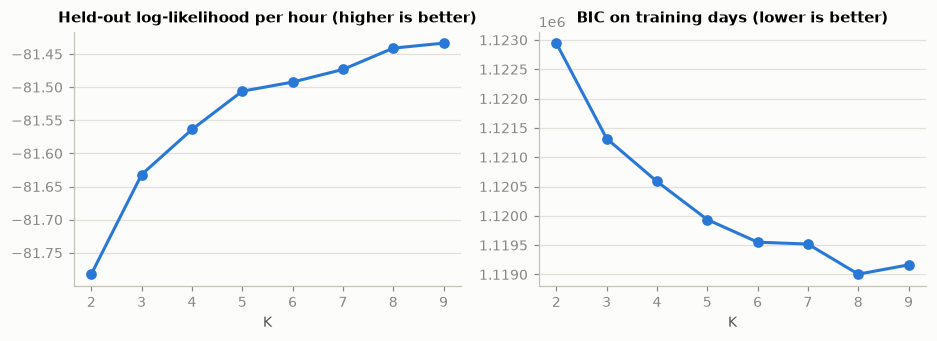

,test_ll_per_hour,bic,restart_ll_range,converged
K,,,,
2,-81.78,1122945.96,0.04,True
3,-81.63,1121318.63,518.25,True
4,-81.56,1120586.24,427.36,True
5,-81.51,1119936.62,811.63,True
6,-81.49,1119551.54,665.03,True
7,-81.47,1119519.10,427.06,True
8,-81.44,1119005.95,913.62,True
9,-81.43,1119164.07,958.16,True


In [10]:
sweep = []
for K in K_RANGE:
    model, restart_scores = fit_best(lambda s: make_trip_mix_hmm(K, s, X_train), X_train, len_train)
    sweep.append({"K": K,
                  "test_ll_per_hour": model.score(X_test, len_test) / len(X_test),
                  "bic": model.bic(X_train, len_train),
                  "restart_ll_range": np.ptp(restart_scores),
                  "converged": model.monitor_.converged})
sweep = pd.DataFrame(sweep).set_index("K")

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(sweep.index, sweep.test_ll_per_hour, "o-", color="#2a78d6", lw=2, ms=6)
axes[0].set(title="Held-out log-likelihood per hour (higher is better)", xlabel="K")
axes[1].plot(sweep.index, sweep.bic, "o-", color="#2a78d6", lw=2, ms=6)
axes[1].set(title="BIC on training days (lower is better)", xlabel="K")
for ax in axes:
    ax.grid(axis="y")
plt.show()
sweep.round(2)

Held-out likelihood keeps improving as K grows (with ~7,000 hourly observations, extra states always find
*some* structure), so we choose K where the gains level off **and** every state can still be named. The
final model below uses `K_FINAL`. Section 7 checks that the main conclusions hold at nearby K.

In [11]:
K_FINAL = 6


def reorder_states(model, order):
    """Permute hidden-state labels in place (works for TripMixHMM, MultinomialHMM and PoissonHMM)."""
    model.startprob_ = model.startprob_[order]
    model.transmat_ = model.transmat_[np.ix_(order, order)]
    for attr in ("emissionprob_", "lambdas_"):
        if hasattr(model, attr):
            setattr(model, attr, getattr(model, attr)[order])
    return model


def order_by_peak_hour(model, X_all):
    """Relabel states by the service hour at which each one is most common."""
    path = model.predict(X_all, [24] * (len(X_all) // 24)).reshape(-1, 24)
    occupancy = np.stack([(path == s).mean(axis=0) for s in range(model.n_components)])
    return reorder_states(model, np.argsort(occupancy.argmax(axis=1), kind="stable"))


final, final_restarts = fit_best(lambda s: make_trip_mix_hmm(K_FINAL, s, X_train), X_train, len_train)
final = order_by_peak_hour(final, X)
paths = final.predict(X, [24] * n_days).reshape(n_days, 24)    # Viterbi path for every day
print(f"restart log-likelihoods: {np.sort(final_restarts)[::-1].round(0)}")

restart log-likelihoods: [-559435. -559521. -559561. -559789. -559792. -559952. -560091. -560091.
 -560096. -560100.]


## 4. Interpreting the final model

### 4.1 Emissions: what each state "looks like"

`B[i,k]` is dominated by the most common type (short member trips), so the heatmap shows **lift**,
$\log_2(B_{i,k} / \text{overall share}_k)$: red = more of this trip type than usual, blue = less. Each cell
also shows the raw share `B[i,k]`.

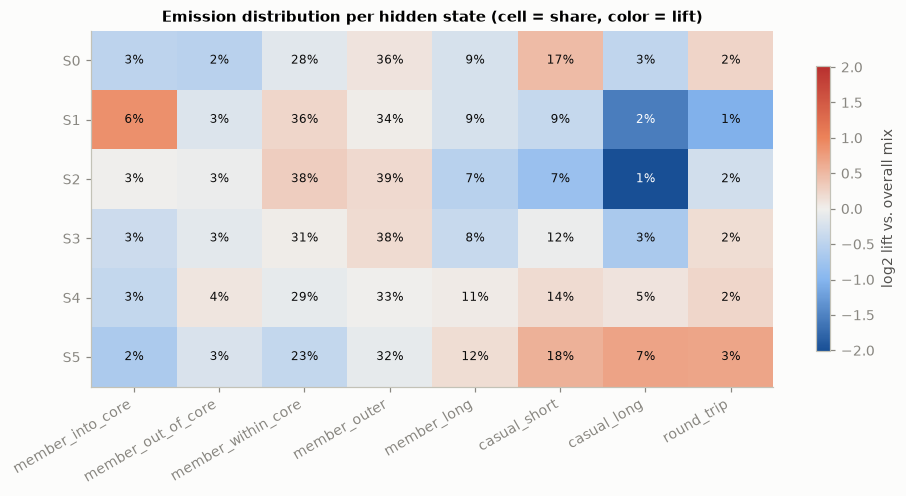

In [12]:
def plot_emission_lift(model, symbols, base_mix, names=None, ax=None):
    B = model.emissionprob_
    lift = np.log2(B / base_mix)
    ax = ax or plt.subplots(figsize=(10, 0.5 * len(B) + 1.2))[1]
    lim = np.abs(lift).max()
    im = ax.imshow(lift, cmap=DIVERGING, vmin=-lim, vmax=lim, aspect="auto")
    for (i, k), share in np.ndenumerate(B):
        ax.text(k, i, f"{share:.0%}", ha="center", va="center", fontsize=8,
                color="#ffffff" if abs(lift[i, k]) > 0.6 * lim else "#0b0b0b")
    ax.set_xticks(range(len(symbols)), symbols, rotation=30, ha="right")
    ax.set_yticks(range(len(B)), names or [f"S{i}" for i in range(len(B))])
    plt.colorbar(im, ax=ax, label="log2 lift vs. overall mix", shrink=0.8)
    return ax


plot_emission_lift(final, TRIP_TYPES, overall_mix)
plt.title("Emission distribution per hidden state (cell = share, color = lift)")
plt.show()

### 4.2 When each state occurs

Share of days in each state at each hour, for workdays vs. non-workdays (weekends + major holidays). The model
was **never told which days are workdays**.

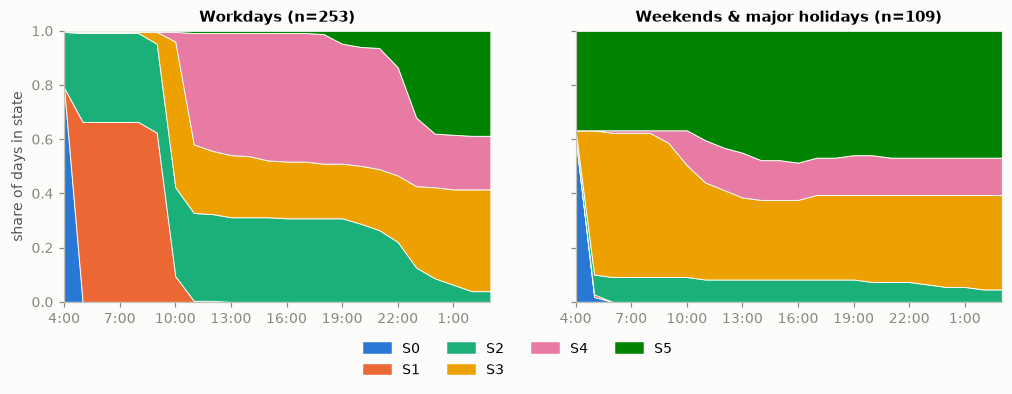

In [13]:
def plot_occupancy(paths, day_groups, names, title_suffix=""):
    fig, axes = plt.subplots(1, len(day_groups), figsize=(5.5 * len(day_groups), 3.2), sharey=True)
    for ax, (label, mask) in zip(np.atleast_1d(axes), day_groups.items()):
        occ = np.stack([(paths[mask] == s).mean(axis=0) for s in range(len(names))])
        ax.stackplot(range(24), occ, colors=STATE_COLORS[:len(names)], edgecolor="#fcfcfb", linewidth=0.6)
        ax.set_xticks(range(0, 24, 3), [f"{h}:00" for h in SERVICE_HOURS[::3]])
        ax.set(xlim=(0, 23), ylim=(0, 1), title=f"{label} (n={mask.sum()}){title_suffix}")
    np.atleast_1d(axes)[0].set_ylabel("share of days in state")
    fig.legend([Patch(color=c) for c in STATE_COLORS[:len(names)]], names, loc="lower center",
               ncol=min(len(names), 4), bbox_to_anchor=(0.5, -0.14))
    plt.show()


workday = days.workday.to_numpy()
STATE_NAMES = [f"S{i}" for i in range(K_FINAL)]
plot_occupancy(paths, {"Workdays": workday, "Weekends & major holidays": ~workday}, STATE_NAMES)

### 4.3 Naming the states

Names below come from reading the lift heatmap (4.1) together with when each state occurs (4.2). They were
assigned for this run (data window, seed, `K_FINAL`). If you change any of those, re-read the plots and
update the list.

In [14]:
STATE_NAMES = [
    "S0 pre-dawn",          # only at 4 AM; few trips, relatively more casual/short
    "S1 morning commute",   # workdays 5–10 AM; most into-core trips, almost no casual/long/round trips
    "S2 winter members",    # whole days Dec–Mar and snow days; casual riding nearly disappears
    "S3 off-peak mix",      # cool-season weekends, late workday mornings and nights; close to the average mix
    "S4 warm workday",      # warm-season workday daytime/evening; slightly more out-of-core and longer trips
    "S5 leisure",           # summer weekends, holidays and late evenings; casual, long and round trips
]
assert len(STATE_NAMES) == K_FINAL
pd.DataFrame(final.emissionprob_, index=STATE_NAMES, columns=TRIP_TYPES).map("{:.1%}".format)

,member_into_core,member_out_of_core,member_within_core,member_outer,member_long,casual_short,casual_long,round_trip
S0 pre-dawn,2.5%,2.3%,28.0%,35.8%,8.9%,16.7%,3.3%,2.4%
S1 morning commute,6.4%,3.0%,36.0%,34.2%,8.9%,9.1%,1.5%,1.0%
S2 winter members,3.4%,3.3%,37.8%,38.6%,7.3%,6.9%,1.1%,1.7%
S3 off-peak mix,2.7%,3.1%,31.2%,38.1%,8.1%,11.7%,2.8%,2.3%
S4 warm workday,2.6%,3.5%,28.9%,33.3%,10.8%,13.6%,4.8%,2.4%
S5 leisure,2.2%,2.9%,22.9%,31.8%,11.8%,17.9%,7.3%,3.3%


### 4.4 Transition matrix

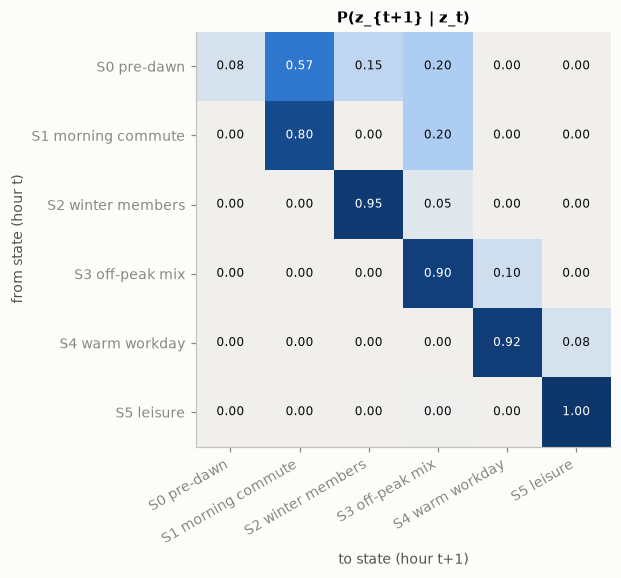

,expected stay (hours)
S0 pre-dawn,1.1
S1 morning commute,5.0
S2 winter members,20.8
S3 off-peak mix,10.2
S4 warm workday,12.6
S5 leisure,216.3


In [15]:
def plot_transmat(model, names):
    A = model.transmat_
    fig, ax = plt.subplots(figsize=(0.75 * len(A) + 2.5, 0.65 * len(A) + 1))
    ax.imshow(A, cmap=SEQUENTIAL, vmin=0, vmax=1)
    for (i, j), p in np.ndenumerate(A):
        ax.text(j, i, f"{p:.2f}", ha="center", va="center", fontsize=8, color="#ffffff" if p > 0.55 else "#0b0b0b")
    ax.set_xticks(range(len(A)), names, rotation=30, ha="right")
    ax.set_yticks(range(len(A)), names)
    ax.set(xlabel="to state (hour t+1)", ylabel="from state (hour t)", title="P(z_{t+1} | z_t)")
    plt.show()


plot_transmat(final, STATE_NAMES)
expected_duration = 1 / (1 - np.diag(final.transmat_))
pd.Series(expected_duration, index=STATE_NAMES).round(1).to_frame("expected stay (hours)")

### 4.5 Viterbi calendar

Each row is a service day and each column an hour (4 AM → 3 AM), colored by the Viterbi state. The strip on the
left marks non-workdays (dark) and rainy days (blue).

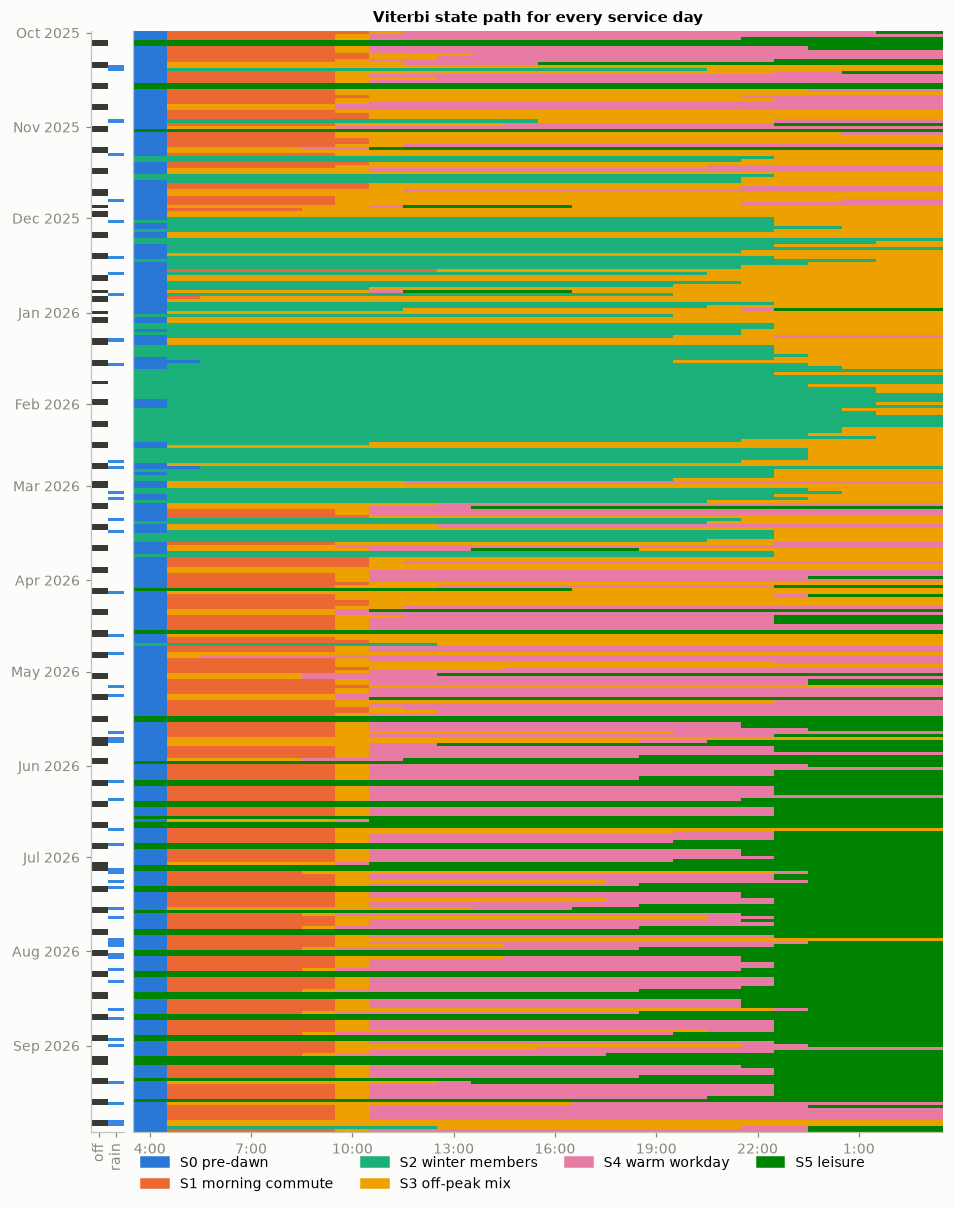

In [16]:
def plot_calendar(paths, names, title):
    fig, (ax_tag, ax) = plt.subplots(1, 2, figsize=(10, 13), gridspec_kw={"width_ratios": [1, 24], "wspace": 0.02})
    tags = np.stack([np.where(workday, 0, 1), np.where(days.rainy, 2, 0)], axis=1)
    ax_tag.imshow(tags, cmap=ListedColormap(["#fcfcfb", "#383835", "#3987e5"]), vmin=0, vmax=2, aspect="auto",
                  interpolation="nearest")
    ax_tag.set_xticks([0, 1], ["off", "rain"], rotation=90)
    month_starts = np.flatnonzero(dates.day == 1)
    ax_tag.set_yticks(month_starts, dates[month_starts].strftime("%b %Y"))
    ax.imshow(paths, cmap=ListedColormap(STATE_COLORS[:len(names)]), vmin=-0.5, vmax=len(names) - 0.5,
              aspect="auto", interpolation="nearest")
    ax.set_xticks(range(0, 24, 3), [f"{h}:00" for h in SERVICE_HOURS[::3]])
    ax.set_yticks([])
    ax.set_title(title)
    fig.legend([Patch(color=c) for c in STATE_COLORS[:len(names)]], names, loc="lower center",
               ncol=min(len(names), 4), bbox_to_anchor=(0.5, 0.06))
    plt.show()


plot_calendar(paths, STATE_NAMES, "Viterbi state path for every service day")

## 5. Are the states meaningful, or just the clock?

### 5.1 Conditional mutual information

A homogeneous HMM has no clock in its transitions, so its states will partly encode time of day. The question
is how much they encode **beyond** the clock. All in bits, over every (day, hour):

- `I(state ; hour)`: how clock-like the states are.
- `I(state ; workday | hour)`: given the hour, how much the state tells you about whether it's a workday.
  A pure-clock model scores 0. The upper bound is `H(workday | hour)`, about 0.86 bits.
- `I(state ; wet hour | hour, workday)`: does the state respond to rain, beyond clock and calendar?

In [17]:
hour_of_row = np.tile(SERVICE_HOURS, n_days)
workday_of_row = np.repeat(workday, 24)
wet_of_row = (weather.precip_mm.to_numpy() >= 0.5)


def bits(a, b):
    return mutual_info_score(a, b) / np.log(2)


def cond_bits(states, target, cond):
    df = pd.DataFrame({"s": states, "t": target, "c": cond})
    return sum(len(g) / len(df) * bits(g.t, g.s) for _, g in df.groupby("c"))


def meaning_scores(path_flat, rows=slice(None)):
    """Mutual-information scores for a flattened Viterbi path (optionally for a subset of hourly rows)."""
    hour, work, wet = hour_of_row[rows], workday_of_row[rows], wet_of_row[rows]
    return {"I(state; hour)": bits(hour, path_flat),
            "I(state; workday | hour)": cond_bits(path_flat, work, hour),
            "I(state; wet | hour, workday)": cond_bits(path_flat, wet, hour * 2 + work)}


clock_only = hour_of_row // 3   # reference: a "model" whose state is just the 3-hour block of the day
pd.DataFrame({"trip-mix HMM": meaning_scores(paths.ravel()),
              "clock (8 three-hour blocks)": meaning_scores(clock_only)}).round(3)

,trip-mix HMM,clock (8 three-hour blocks)
I(state; hour),0.548,3.0
I(state; workday | hour),0.300,0.0
"I(state; wet | hour, workday)",0.027,0.0


### 5.2 Holidays: do they decode like workdays or like weekends?

For each holiday, compare its Viterbi path with the typical workday and the typical weekend:
**agreement** = average over hours of P(reference day is in the holiday's state at that hour). The model
never saw the holiday labels.

In [18]:
def reference_occupancy(mask):
    return np.stack([(paths[mask] == s).mean(axis=0) for s in range(K_FINAL)])   # (K, 24)


weekend = np.asarray(dates.dayofweek >= 5) & days.holiday.isna().to_numpy()
plain_workday = workday & days.holiday.isna().to_numpy()
occ_work, occ_weekend = reference_occupancy(plain_workday), reference_occupancy(weekend)

holiday_rows = []
for d in np.flatnonzero(days.holiday.notna()):
    agree_work = occ_work[paths[d], np.arange(24)].mean()
    agree_weekend = occ_weekend[paths[d], np.arange(24)].mean()
    holiday_rows.append({"date": dates[d].date(), "weekday": days.weekday.iloc[d], "holiday": days.holiday.iloc[d],
                         "major": days.holiday.iloc[d] in MAJOR_HOLIDAYS,
                         "agree_workday": agree_work, "agree_weekend": agree_weekend,
                         "decodes_like": "weekend" if agree_weekend > agree_work else "workday"})
pd.DataFrame(holiday_rows).round(2)

,date,weekday,holiday,major,agree_workday,agree_weekend,decodes_like
0,2025-10-13,Monday,Columbus Day,False,0.33,0.18,workday
1,2025-11-11,Tuesday,Veterans Day,False,0.30,0.14,workday
2,2025-11-27,Thursday,Thanksgiving Day,True,0.20,0.39,weekend
3,2025-12-25,Thursday,Christmas Day,True,0.20,0.39,weekend
4,2026-01-01,Thursday,New Year's Day,True,0.24,0.37,weekend
5,2026-01-19,Monday,"Birthday of Martin Luther King, Jr.",False,0.31,0.14,workday
6,2026-02-16,Monday,Washington's Birthday,False,0.30,0.13,workday
7,2026-05-25,Monday,Memorial Day,True,0.19,0.45,weekend
8,2026-06-19,Friday,Juneteenth National Independence Day,False,0.13,0.46,weekend
9,2026-07-03,Friday,Independence Day,True,0.13,0.46,weekend


Labor Day (Mon Sep 7, 2026) next to the Mondays and Sundays around it:

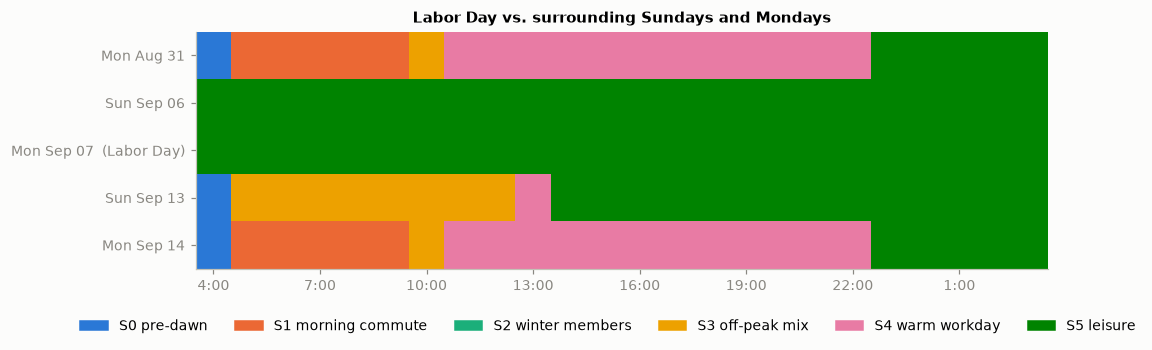

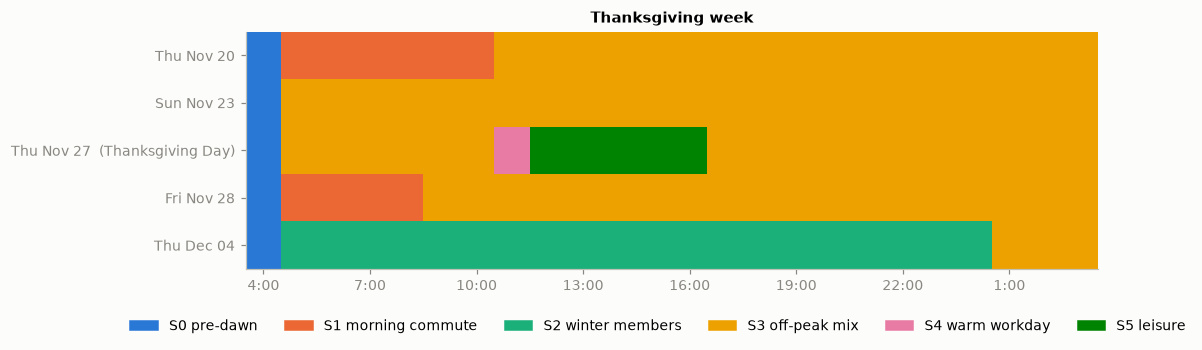

In [19]:
def plot_day_strips(day_list, names, title):
    idx = [dates.get_loc(pd.Timestamp(d)) for d in day_list]
    fig, ax = plt.subplots(figsize=(10, 0.38 * len(idx) + 0.9))
    ax.imshow(paths[idx], cmap=ListedColormap(STATE_COLORS[:len(names)]), vmin=-0.5, vmax=len(names) - 0.5,
              aspect="auto", interpolation="nearest")
    ax.set_yticks(range(len(idx)), [f"{dates[i]:%a %b %d}" + (f"  ({days.holiday.iloc[i]})" if pd.notna(days.holiday.iloc[i]) else "")
                                    for i in idx])
    ax.set_xticks(range(0, 24, 3), [f"{h}:00" for h in SERVICE_HOURS[::3]])
    ax.set_title(title)
    fig.legend([Patch(color=c) for c in STATE_COLORS[:len(names)]], names, loc="lower center",
               ncol=min(len(names), 6), bbox_to_anchor=(0.5, -0.12 - 0.02 * (6 - len(idx))))
    plt.show()


def available(day_list):
    return [d for d in day_list if pd.Timestamp(d) in dates]


plot_day_strips(available(["2026-08-31", "2026-09-06", "2026-09-07", "2026-09-13", "2026-09-14"]), STATE_NAMES,
                "Labor Day vs. surrounding Sundays and Mondays")
plot_day_strips(available(["2025-11-20", "2025-11-23", "2025-11-27", "2025-11-28", "2025-12-04"]), STATE_NAMES,
                "Thanksgiving week")

### 5.3 Weather

On **workdays only** (so the calendar is held fixed), the share of daytime hours (7 AM – 9 PM) spent in each
state on rainy vs. dry days, and on the snowiest days.

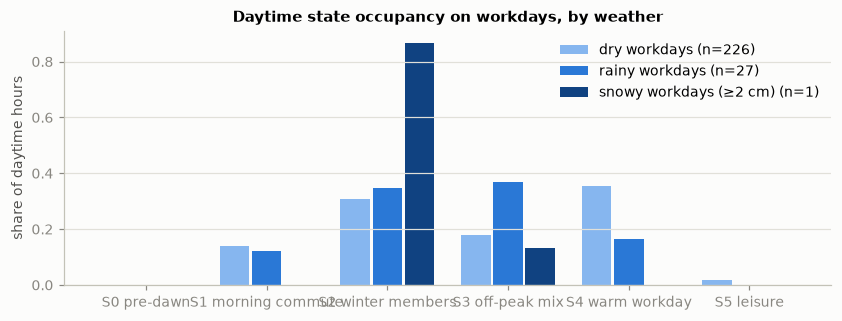

,dry workdays,rainy workdays,snowy workdays (≥2 cm)
S0 pre-dawn,0.000,0.000,0.000
S1 morning commute,0.139,0.123,0.000
S2 winter members,0.308,0.346,0.867
S3 off-peak mix,0.180,0.368,0.133
S4 warm workday,0.355,0.163,0.000
S5 leisure,0.019,0.000,0.000


In [20]:
daytime_cols = [SERVICE_HOURS.index(h) for h in range(7, 22)]


def daytime_share(mask):
    p = paths[mask][:, daytime_cols]
    return np.array([(p == s).mean() for s in range(K_FINAL)])


snowy = (days.snow_cm >= 2).to_numpy()
groups = {"dry workdays": workday & ~days.rainy.to_numpy() & ~snowy,
          "rainy workdays": workday & days.rainy.to_numpy(),
          "snowy workdays (≥2 cm)": workday & snowy}
weather_table = pd.DataFrame({k: daytime_share(m) for k, m in groups.items()}, index=STATE_NAMES)

fig, ax = plt.subplots(figsize=(9, 3))
width = 0.8 / len(groups)
for g, (label, col) in enumerate(weather_table.items()):
    ax.bar(np.arange(K_FINAL) + (g - (len(groups) - 1) / 2) * width, col, width * 0.92,
           color=["#86b6ef", "#2a78d6", "#104281"][g], label=f"{label} (n={groups[label].sum()})")
ax.set_xticks(range(K_FINAL), STATE_NAMES)
ax.set_ylabel("share of daytime hours")
ax.set_title("Daytime state occupancy on workdays, by weather")
ax.legend()
ax.grid(axis="y")
plt.show()
weather_table.round(3)

## 6. Prediction: next-hour trip mix

Task: on **held-out days**, given the hours so far today, predict the trip-type mix of the next hour.

The HMM uses the **forward filter**: $P(z_{t+1} \mid x_{1..t}) = \text{normalize}(\alpha_t)\,A$, and the predicted
mix is $P(z_{t+1} \mid x_{1..t})\, B$. The metric is **cross-entropy per trip**,
$-\frac{1}{N}\sum_t \sum_k n_{t,k} \log q_{t,k}$ (in bits; lower is better).

Baselines estimated from the training days:
- overall average mix,
- average mix for that hour of day,
- average mix for (hour, workday/non-workday). **This one is given the calendar; the HMM isn't.**
- persistence: last hour's mix (add-one smoothed).

In [21]:
def hmm_predictive_mix(model, X_day):
    """Forward filter over one day: predicted emission distribution for each hour given earlier hours."""
    log_lik = model._compute_log_likelihood(X_day)
    prior, preds = model.startprob_, []
    for t in range(len(X_day)):
        preds.append(prior @ model.emissionprob_)
        post = prior * np.exp(log_lik[t] - log_lik[t].max())
        prior = (post / post.sum()) @ model.transmat_
    return np.array(preds)


def cross_entropy_bits(counts, preds):
    return -(counts * np.log2(preds)).sum() / counts.sum()


def mix_table(counts, keys):
    table = pd.DataFrame(counts).groupby(keys).sum() + 1
    return table.div(table.sum(axis=1), axis=0)


def evaluate_predictions(model, X_model, X_raw):
    """Cross-entropy of each predictor on the held-out days, split by day type."""
    train_rows, _ = day_rows(X_raw, train_days)
    train_hour = np.tile(np.arange(24), len(train_days))
    train_work = np.repeat(workday[train_days], 24)
    by_hour = mix_table(train_rows, train_hour).to_numpy()
    by_hour_work = mix_table(train_rows, [train_hour, train_work])
    overall = (train_rows.sum(0) + 1) / (train_rows.sum() + train_rows.shape[1])

    preds = {name: [] for name in ["overall mix", "hour of day", "hour + workday (given calendar)",
                                   "persistence", "HMM forward filter"]}
    for d in test_days:
        raw = X_raw[d * 24:(d + 1) * 24]
        preds["overall mix"].append(np.tile(overall, (24, 1)))
        preds["hour of day"].append(by_hour)
        preds["hour + workday (given calendar)"].append(by_hour_work.xs(workday[d], level=1).to_numpy())
        last = np.vstack([overall, (raw[:-1] + 1) / (raw[:-1] + 1).sum(axis=1, keepdims=True)])
        preds["persistence"].append(last)
        preds["HMM forward filter"].append(hmm_predictive_mix(model, X_model[d * 24:(d + 1) * 24]))

    test_raw = np.stack([X_raw[d * 24:(d + 1) * 24] for d in test_days])
    subsets = {"all test days": np.ones(len(test_days), bool),
               "workdays": workday[test_days], "non-workdays": ~workday[test_days],
               "holidays + rainy days": (days.holiday.notna() | days.rainy).to_numpy()[test_days]}
    return pd.DataFrame({sub: {name: cross_entropy_bits(test_raw[m], np.stack(p)[m]) for name, p in preds.items()}
                         for sub, m in subsets.items()})


prediction_table = evaluate_predictions(final, X, X_counts)
prediction_table.round(4)

,all test days,workdays,non-workdays,holidays + rainy days
overall mix,2.4248,2.3760,2.5442,2.4357
hour of day,2.4093,2.3572,2.5366,2.4276
hour + workday (given calendar),2.3983,2.3551,2.5039,2.4033
persistence,2.3888,2.3469,2.4911,2.3897
HMM forward filter,2.3981,2.3565,2.4996,2.3966


## 7. Ablations

Each ablation refits at `K_FINAL` on the training days (10 restarts) and changes **one** thing.

### 7.1 Effective sample size `N_EFF`

- **mean max posterior:** average confidence of the smoothed state posterior on held-out days.
- **switches / day:** number of Viterbi state changes per day.
- **prediction CE:** held-out next-hour cross-entropy (bits/trip). It's comparable across `N_EFF` because the
  predicted *mix* doesn't depend on the scale.

In [22]:
def ablation_fit(X_model, K=K_FINAL):
    X_tr, l_tr = day_rows(X_model, train_days)
    model, scores = fit_best(lambda s: make_trip_mix_hmm(K, s, X_tr), X_tr, l_tr)
    return order_by_peak_hour(model, X_model)


neff_rows = []
for n_eff in [5, 20, 50, 200, None]:
    X_n = temper(X_counts, n_eff)
    model = ablation_fit(X_n)
    p = model.predict(X_n, [24] * n_days).reshape(n_days, 24)
    X_te, l_te = day_rows(X_n, test_days)
    neff_rows.append({"N_eff": "raw counts" if n_eff is None else n_eff,
                      "mean max posterior": model.predict_proba(X_te, l_te).max(axis=1).mean(),
                      "switches / day": (np.diff(p, axis=1) != 0).sum(axis=1).mean(),
                      "prediction CE": evaluate_predictions(model, X_n, X_counts).loc["HMM forward filter", "all test days"],
                      **meaning_scores(p.ravel())})
pd.DataFrame(neff_rows).set_index("N_eff").round(3)

,mean max posterior,switches / day,prediction CE,I(state; hour),I(state; workday | hour),"I(state; wet | hour, workday)"
N_eff,,,,,,
5,0.741,2.517,2.407,0.512,0.097,0.017
20,0.777,2.630,2.401,0.441,0.216,0.023
50,0.892,2.227,2.398,0.548,0.300,0.027
200,0.932,3.144,2.396,0.662,0.373,0.040
raw counts,0.981,5.066,2.394,0.523,0.287,0.035


### 7.2 Trip-type alphabet

Which features create the meaningful states?
- `full`: the 8 types
- `no_direction`: the four member-short direction types merged into one `member_short` (5 types)
- `no_rider_type`: member/casual merged; keeps direction for short trips (6 types)

If direction is what separates the morning and evening commutes, then without it those two states should merge
(compare the workday occupancy plots below).

,I(state; hour),I(state; workday | hour),"I(state; wet | hour, workday)"
alphabet,,,
full (8 types),0.548,0.300,0.027
no_direction (5 types),0.372,0.195,0.028
no_rider_type (6 types),0.703,0.308,0.024


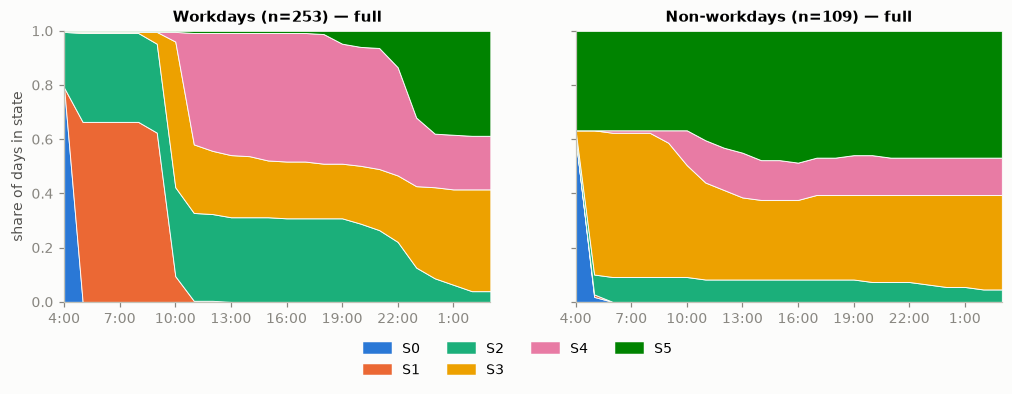

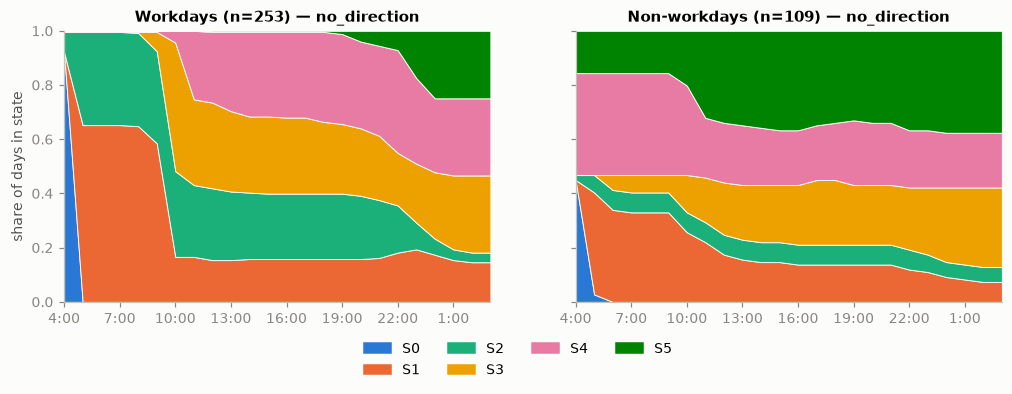

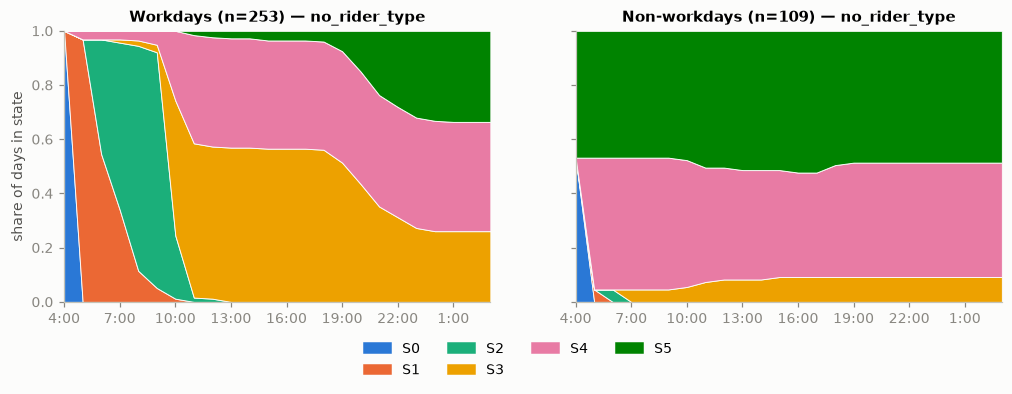

In [23]:
alphabet_rows, alphabet_paths = [], {}
for name in ALPHABETS:
    X_a_counts, symbols = alphabet_counts(name)
    model = ablation_fit(temper(X_a_counts))
    p = model.predict(temper(X_a_counts), [24] * n_days).reshape(n_days, 24)
    alphabet_paths[name] = p
    alphabet_rows.append({"alphabet": f"{name} ({len(symbols)} types)", **meaning_scores(p.ravel())})
display(pd.DataFrame(alphabet_rows).set_index("alphabet").round(3))

for name, p in alphabet_paths.items():
    plot_occupancy(p, {"Workdays": workday, "Non-workdays": ~workday}, [f"S{i}" for i in range(K_FINAL)],
                   title_suffix=f" — {name}")

### 7.3 Volume vs. mix: the core design choice

Same K, three observation models:
- **Poisson on total trips:** one count per hour (`hmmlearn.hmm.PoissonHMM`). This is the "how busy is it" model.
- **Poisson on per-type counts:** 8 counts per hour, raw volume included. This is the count-based design we
  started from.
- **Trip-mix (ours):** composition only.

The prediction says count-based states collapse into busy/quiet levels that follow the clock. That would mean
high `I(state; hour)` and low `I(state; workday | hour)`.

state rates (trips/hour): [  432.  1583.  3769.  6626.  9866. 14875.]


,I(state; hour),I(state; workday | hour),"I(state; wet | hour, workday)"
trip-mix (ours),0.548,0.300,0.027
Poisson on total trips,0.759,0.147,0.050
Poisson on per-type counts,0.787,0.169,0.049


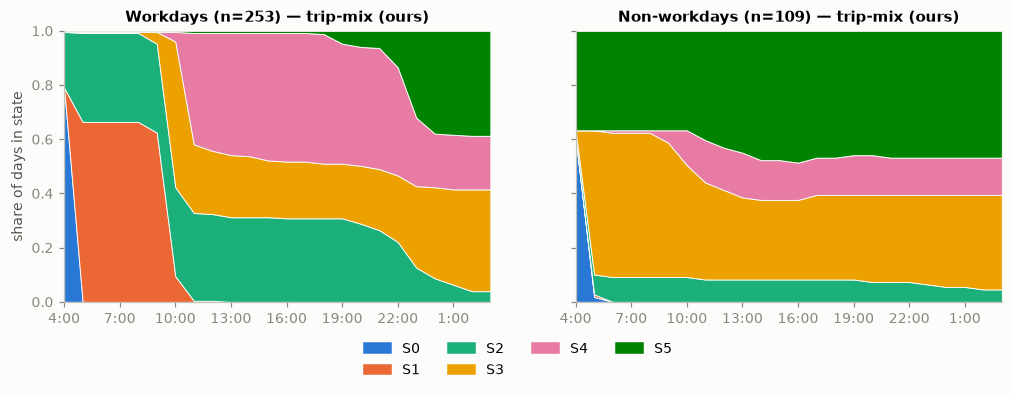

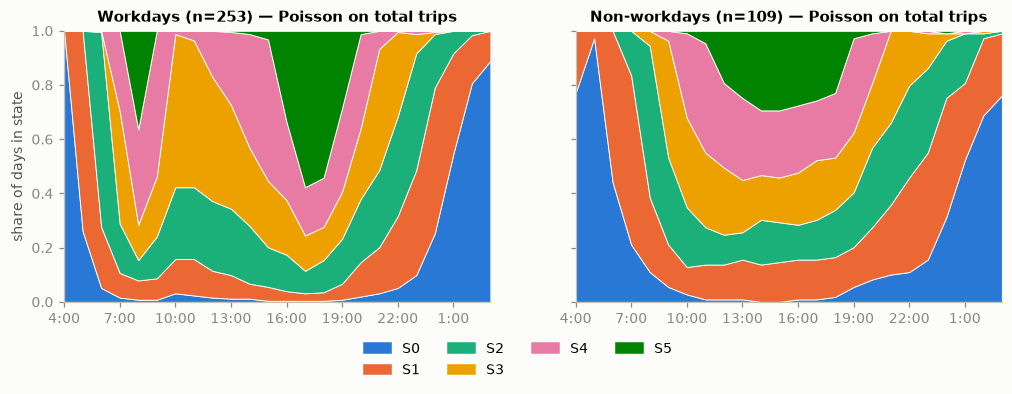

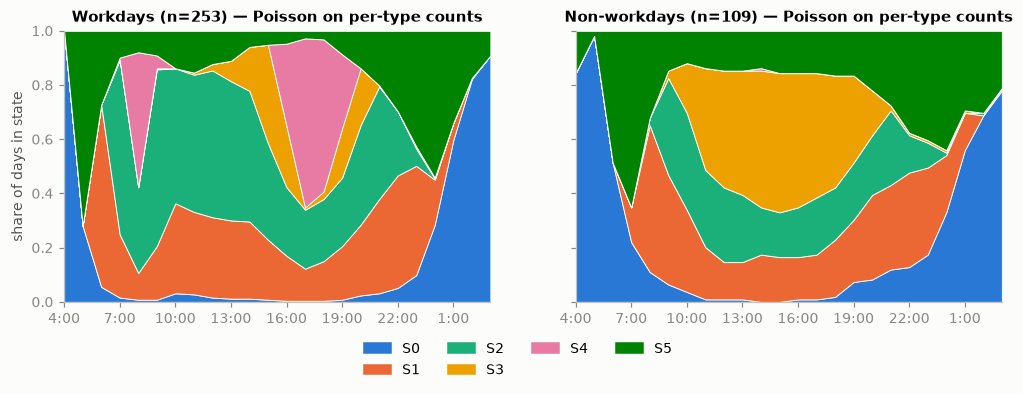

In [24]:
def make_poisson_hmm(K, seed, X):
    """Poisson rates start at the counts of K random hours (+1), mirroring make_trip_mix_hmm."""
    rng = np.random.default_rng(seed)
    model = hmm.PoissonHMM(n_components=K, n_iter=500, tol=EM_TOL, random_state=seed, init_params="st")
    model.lambdas_ = X[rng.choice(len(X), K, replace=False)] + 1.0
    return model


volume_models = {"Poisson on total trips": X_counts.sum(axis=1, keepdims=True),
                 "Poisson on per-type counts": X_counts}
volume_rows, volume_paths = [], {"trip-mix (ours)": paths}
for name, X_v in volume_models.items():
    X_tr, l_tr = day_rows(X_v, train_days)
    model, _ = fit_best(lambda s: make_poisson_hmm(K_FINAL, s, X_tr), X_tr, l_tr)
    model = order_by_peak_hour(model, X_v)
    volume_paths[name] = model.predict(X_v, [24] * n_days).reshape(n_days, 24)
    if name == "Poisson on total trips":
        print("state rates (trips/hour):", np.sort(model.lambdas_.ravel()).round(0))

volume_table = pd.DataFrame({name: meaning_scores(p.ravel()) for name, p in volume_paths.items()}).T
display(volume_table.round(3))

for name, p in volume_paths.items():
    plot_occupancy(p, {"Workdays": workday, "Non-workdays": ~workday}, [f"S{i}" for i in range(K_FINAL)],
                   title_suffix=f" — {name}")

### 7.4 Robustness to K

The meaning scores for the trip-mix model at K = 4…8. Does the conclusion depend on the exact K?

In [25]:
k_rows = []
for K in range(4, 9):
    model = ablation_fit(X, K)
    p = model.predict(X, [24] * n_days).reshape(n_days, 24)
    k_rows.append({"K": K, **meaning_scores(p.ravel()),
                   "prediction CE": evaluate_predictions(model, X, X_counts).loc["HMM forward filter", "all test days"]})
pd.DataFrame(k_rows).set_index("K").round(3)

,I(state; hour),I(state; workday | hour),"I(state; wet | hour, workday)",prediction CE
K,,,,
4,0.412,0.198,0.015,2.401
5,0.471,0.344,0.024,2.399
6,0.548,0.300,0.027,2.398
7,0.799,0.308,0.025,2.398
8,0.785,0.446,0.030,2.396


### 7.5 Holding season fixed: a warm-season model

The full-year model spends two states (S2 winter, S5 leisure) mostly on *season*. Here a model with the same K
is fitted on **May–September only**, so its states have to explain variation within a season. The question is
whether that capacity goes to finer within-day modes, like a separate evening-commute state. Scores are
compared with the full-year model on the same warm-season hours.

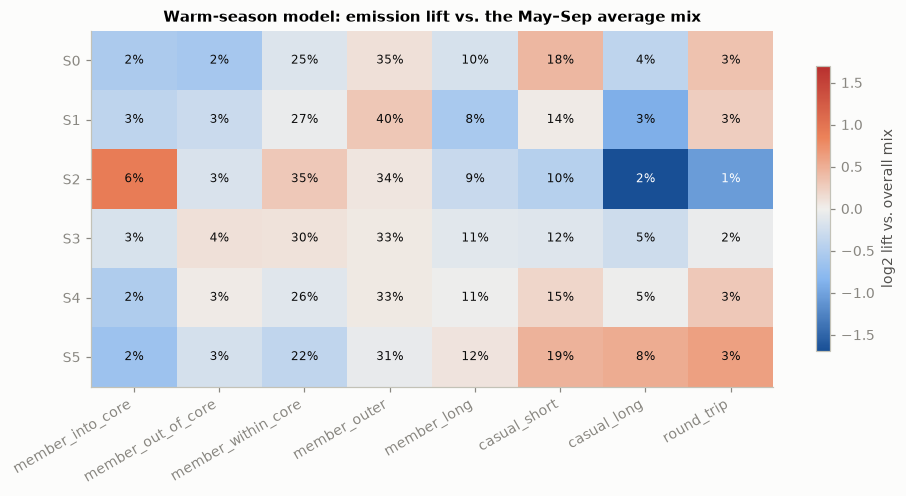

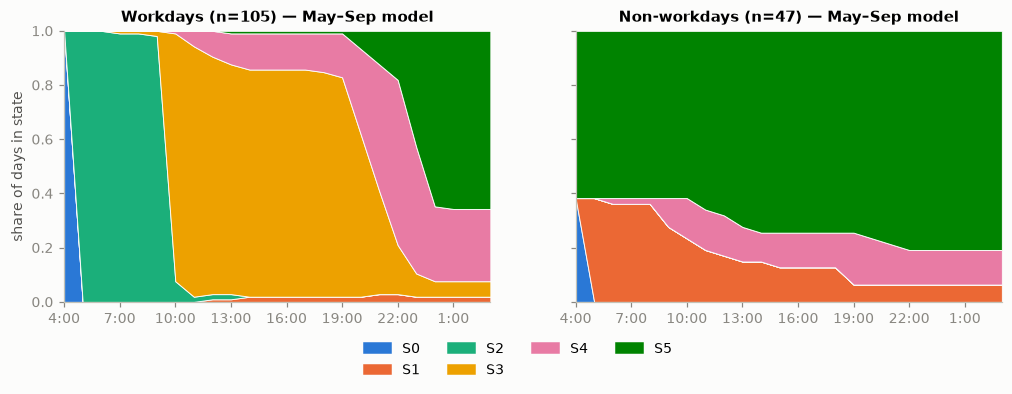

,full-year model (warm hours),warm-season model
I(state; hour),0.793,0.846
I(state; workday | hour),0.456,0.568
"I(state; wet | hour, workday)",0.109,0.096


In [26]:
warm = np.asarray(dates.month.isin([5, 6, 7, 8, 9]))
warm_days = np.flatnonzero(warm)
X_tr, l_tr = day_rows(X, np.flatnonzero(warm & ~test_mask))
warm_model, _ = fit_best(lambda s: make_trip_mix_hmm(K_FINAL, s, X_tr), X_tr, l_tr)
X_warm, l_warm = day_rows(X, warm_days)
warm_model = order_by_peak_hour(warm_model, X_warm)
warm_paths = warm_model.predict(X_warm, l_warm).reshape(-1, 24)

warm_counts, _ = day_rows(X_counts, warm_days)
plot_emission_lift(warm_model, TRIP_TYPES, warm_counts.sum(0) / warm_counts.sum())
plt.title("Warm-season model: emission lift vs. the May–Sep average mix")
plt.show()
plot_occupancy(warm_paths, {"Workdays": workday[warm], "Non-workdays": ~workday[warm]},
               [f"S{i}" for i in range(K_FINAL)], title_suffix=" — May–Sep model")

warm_rows = np.repeat(warm, 24)
pd.DataFrame({"full-year model (warm hours)": meaning_scores(paths[warm].ravel(), warm_rows),
              "warm-season model": meaning_scores(warm_paths.ravel(), warm_rows)}).round(3)

## 8. Stretch: a day-level HMM

Summarize each day by **how many hours it spent in each hourly state** (a count vector summing to 24) and fit a
second HMM over the sequence of days (`hmmlearn.hmm.MultinomialHMM`, `n_trials=24`). Its hidden states are
*day types*, and its transitions describe how day types follow each other. All usable days form one
sequence. Excluded data-gap days break the sequence into segments.

Expected hours per hourly state, for each day type:


,S0 pre-dawn,S1 morning commute,S2 winter members,S3 off-peak mix,S4 warm workday,S5 leisure,days,% workdays,% rainy,mean max temp °C
D0,0.4,0.0,18.7,4.6,0.1,0.1,93,89.2,14.0,2.8
D1,1.0,4.4,0.0,1.9,13.1,3.5,138,89.1,7.2,24.4
D2,1.0,3.1,0.0,18.2,1.0,0.7,78,57.7,23.1,12.4
D3,0.2,0.0,0.0,1.5,0.5,21.8,53,3.8,17.0,26.2


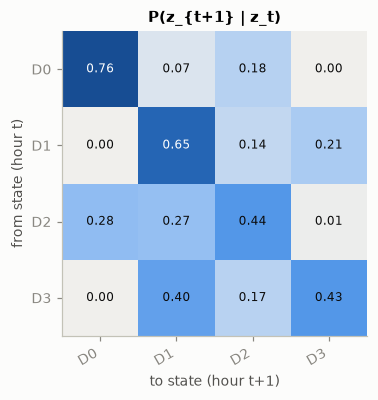

In [27]:
K_DAY = 4
day_obs = np.stack([(paths == s).sum(axis=1) for s in range(K_FINAL)], axis=1)

# Split the day sequence wherever a calendar day was dropped (data gaps).
breaks = np.flatnonzero(np.diff(dates).astype("timedelta64[D]").astype(int) > 1) + 1
day_lengths = np.diff(np.r_[0, breaks, n_days]).tolist()

day_model, _ = fit_best(lambda s: hmm.MultinomialHMM(n_components=K_DAY, n_trials=24, n_iter=500, tol=EM_TOL,
                                                     random_state=s), day_obs, day_lengths)
day_states = day_model.predict(day_obs, day_lengths)

# Order day types by how workday-like they are, so labels are stable across runs.
work_share = np.array([workday[day_states == s].mean() if (day_states == s).any() else 0 for s in range(K_DAY)])
order = np.argsort(-work_share)
day_model = reorder_states(day_model, order)
day_states = np.argsort(order)[day_states]
DAY_NAMES = [f"D{i}" for i in range(K_DAY)]

profile = pd.DataFrame(day_model.emissionprob_ * 24, index=DAY_NAMES, columns=STATE_NAMES).round(1)
profile["days"] = np.bincount(day_states, minlength=K_DAY)
profile["% workdays"] = [workday[day_states == s].mean() * 100 for s in range(K_DAY)]
profile["% rainy"] = [days.rainy.to_numpy()[day_states == s].mean() * 100 for s in range(K_DAY)]
profile["mean max temp °C"] = [days.max_temp_c.to_numpy()[day_states == s].mean() for s in range(K_DAY)]
print("Expected hours per hourly state, for each day type:")
display(profile.round(1))
plot_transmat(day_model, DAY_NAMES)

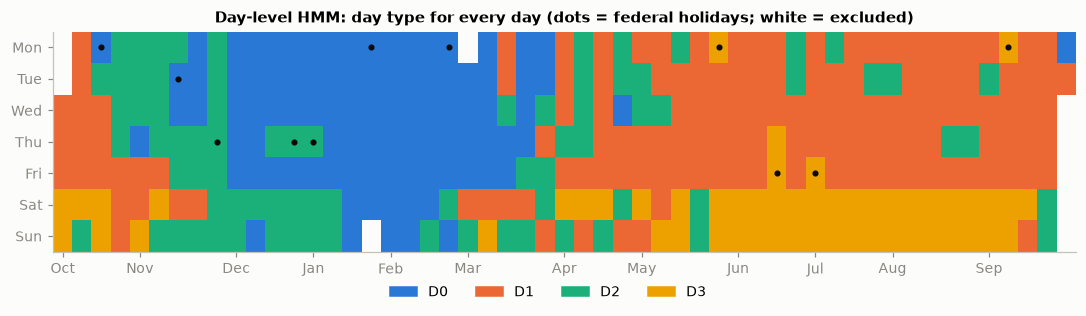

In [28]:
# Calendar view: weeks as columns, weekdays as rows.
cal = pd.DataFrame({"date": dates, "state": day_states})
cal["week"] = (cal.date - pd.to_timedelta(cal.date.dt.dayofweek, unit="D")).rank(method="dense").astype(int) - 1
grid = np.full((7, cal.week.max() + 1), np.nan)
grid[cal.date.dt.dayofweek, cal.week] = cal.state

fig, ax = plt.subplots(figsize=(12, 2.6))
ax.imshow(grid, cmap=ListedColormap(STATE_COLORS[:K_DAY]), vmin=-0.5, vmax=K_DAY - 0.5, aspect="auto",
          interpolation="nearest")
ax.set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
first_weeks = cal.groupby(cal.date.dt.to_period("M")).week.min()
ax.set_xticks(first_weeks.to_numpy(), [p.strftime("%b") for p in first_weeks.index])
for _, row in cal[days.holiday.notna().to_numpy()].iterrows():
    ax.plot(row.week, row.date.dayofweek, marker="o", ms=3, color="#0b0b0b")
ax.set_title("Day-level HMM: day type for every day (dots = federal holidays; white = excluded)")
fig.legend([Patch(color=c) for c in STATE_COLORS[:K_DAY]], DAY_NAMES, loc="lower center", ncol=K_DAY,
           bbox_to_anchor=(0.5, -0.1))
plt.show()

## 9. Summary

See the results section of [`TRIP_MIX_HMM.md`](TRIP_MIX_HMM.md) for the interpretation of these outputs.